# 04 · 독성 예측 분류 모델 (Tox21)
### 실습으로 배우는 신약개발 AI — 강의 목차 ⑥ 독성 예측 분류 모델

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/04_Toxicity_Classification_Tox21.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① 독성 데이터(Tox21) 이해 ② **불균형 분류** 다루기 (class_weight, 임계값 조정, 비용 기반 판단) ③ ROC vs PR 곡선 ④ 독성 부분구조 해석 ⑤ 다중 엔드포인트(멀티태스크) 예측 |
| **데이터** | Tox21 (미국 NIH·EPA·FDA 공동, 약 7,800 화합물 × 12개 독성 시험) |
| **실행 환경** | CPU · 약 10분 |

> 신약 후보의 **약 30%가 독성 때문에 탈락**합니다. 독성 예측에서 가장 비싼 실수는 **독성 물질을 안전하다고 판정(위음성, FN)** 하는 것입니다.

In [2]:
%pip install -q rdkit koreanize-matplotlib
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'
from rdkit import Chem, RDLogger; RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import Draw, Descriptors, rdFingerprintGenerator
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay)
print("✅ 준비 완료")

✅ 준비 완료


## 1. Tox21 데이터 이해
| 그룹 | 시험(엔드포인트) | 의미 |
|---|---|---|
| **NR** (Nuclear Receptor, 핵수용체) | NR-AR, NR-AR-LBD, NR-AhR, NR-Aromatase, NR-ER, NR-ER-LBD, NR-PPAR-gamma | 호르몬 교란(내분비계 독성) |
| **SR** (Stress Response, 스트레스 반응) | SR-ARE, SR-ATAD5, SR-HSE, **SR-MMP**, SR-p53 | 산화 스트레스, DNA 손상, **미토콘드리아 막전위 교란** 등 세포독성 |

- 값: 1 = 독성 반응(양성), 0 = 음성, 빈칸 = 시험하지 않음(결측)

In [3]:
tox = pd.read_csv("https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz")
tasks = [c for c in tox.columns if c.startswith(("NR-", "SR-"))]
print("화합물 수:", len(tox), " / 독성 시험 수:", len(tasks))
stat = pd.DataFrame({"시험된 화합물": tox[tasks].notna().sum(), "양성 비율(%)": (tox[tasks].mean() * 100).round(1)})
stat.sort_values("양성 비율(%)")

화합물 수: 7831  / 독성 시험 수: 12


,시험된 화합물,양성 비율(%)
NR-PPAR-gamma,6450,2.9
NR-AR-LBD,6758,3.5
SR-ATAD5,7072,3.7
NR-AR,7265,4.3
NR-ER-LBD,6955,5.0
NR-Aromatase,5821,5.2
SR-HSE,6467,5.8
SR-p53,6774,6.2
NR-AhR,6549,11.7
NR-ER,6193,12.8


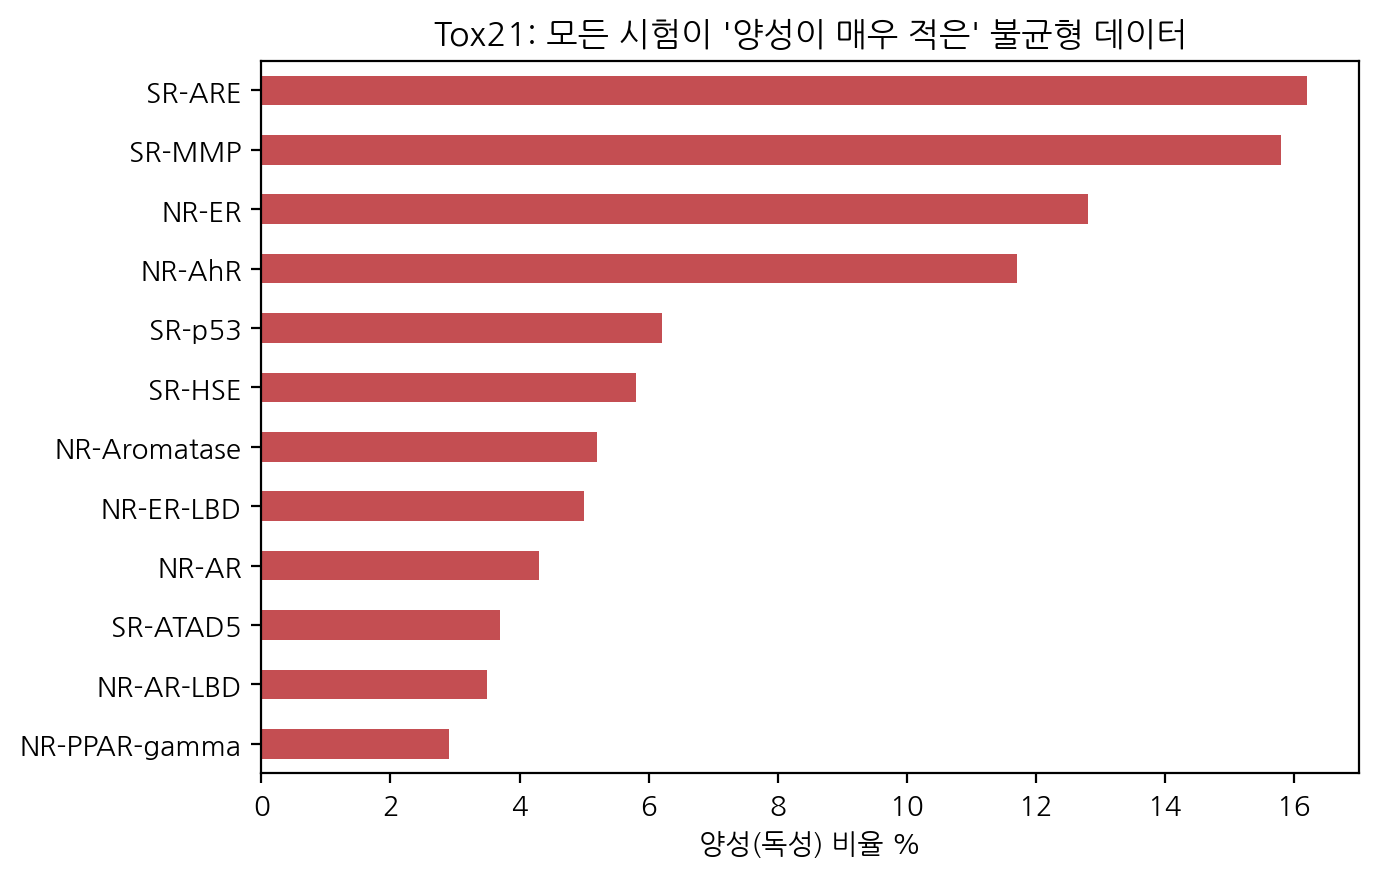

In [4]:
stat["양성 비율(%)"].sort_values().plot.barh(figsize=(7, 4.5), color="#C44E52")
plt.xlabel("양성(독성) 비율 %"); plt.title("Tox21: 모든 시험이 '양성이 매우 적은' 불균형 데이터"); plt.tight_layout(); plt.show()

## 2. 미토콘드리아 독성 (SR-MMP) 예측 데이터 준비
**SR-MMP**: 미토콘드리아 막전위(MMP)를 무너뜨리는 화합물 → 간·심장 독성의 주요 원인 중 하나.
특성: Morgan 지문(2048) + 전체 RDKit 기술자.

In [5]:
TASK = "SR-MMP"
d = tox[["smiles", TASK]].dropna().reset_index(drop=True)
d["mol"] = d["smiles"].apply(Chem.MolFromSmiles)
d = d[d["mol"].notna()].reset_index(drop=True)

morgan = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X_fp = np.array([morgan.GetFingerprintAsNumPy(m) for m in d["mol"]])
X_desc = pd.DataFrame([Descriptors.CalcMolDescriptors(m) for m in d["mol"]]).replace([np.inf, -np.inf], np.nan)
X_desc = X_desc.fillna(X_desc.median()).clip(-1e6, 1e6)
X = np.hstack([X_fp, X_desc.values])
y = d[TASK].astype(int).values
print("X:", X.shape, f"  양성(독성) {y.sum()}개 = {y.mean()*100:.1f}%")

# 학습 / 검증(임계값 선택용) / 평가 = 60 / 20 / 20, 클래스 비율 유지
X_tmp, X_te, y_tmp, y_te, i_tmp, i_te = train_test_split(X, y, np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42)
print("학습/검증/평가:", len(y_tr), len(y_va), len(y_te))

X: (5804, 2265)   양성(독성) 918개 = 15.8%
학습/검증/평가: 3482 1161 1161


## 3. 정확도의 함정 — '전부 음성' 바보 모델과 비교

In [7]:
def report(name, y_true, proba, th=0.5):
    p = (proba >= th).astype(int)
    return {"모델": name, "임계값": th, "정확도": accuracy_score(y_true, p), "정밀도": precision_score(y_true, p, zero_division=0),
            "재현율": recall_score(y_true, p), "F1": f1_score(y_true, p),
            "ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba)}

dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42).fit(X_tr, y_tr)
rf_bal = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42,
                                class_weight="balanced_subsample", min_samples_leaf=2).fit(X_tr, y_tr)

rows = [report("전부 음성(바보 모델)", y_te, dummy.predict_proba(X_te)[:, 1]),
        report("랜덤포레스트 (기본)", y_te, rf.predict_proba(X_te)[:, 1]),
        report("랜덤포레스트 (class_weight)", y_te, rf_bal.predict_proba(X_te)[:, 1])]
pd.DataFrame(rows).round(3)

,모델,임계값,정확도,정밀도,재현율,F1,ROC-AUC,PR-AUC
0,전부 음성(바보 모델),0.5,0.842,0.000,0.000,0.000,0.500,0.158
1,랜덤포레스트 (기본),0.5,0.895,0.878,0.391,0.541,0.908,0.718
2,랜덤포레스트 (class_weight),0.5,0.897,0.820,0.446,0.577,0.911,0.734


> 바보 모델도 정확도는 85% 근처! 하지만 **재현율 0** — 독성 물질을 하나도 못 찾습니다.
> 기본 랜덤포레스트도 임계값 0.5 에서는 재현율이 낮습니다. 확률 점수는 좋지만(**AUC 높음**) **판정 기준(임계값)이 업무 목적과 맞지 않기** 때문입니다.

## 4. ⭐ 임계값 조정 — 검증 데이터로 정하고, 평가 데이터로 확인
- 방법 1: 검증 세트에서 **F1 이 최대**가 되는 임계값
- 방법 2: **재현율 ≥ 80%** 를 보장하는 가장 높은 임계값 (독성 스크리닝 실무형)
- ⚠️ 임계값을 평가 세트로 고르면 성능이 부풀려집니다(데이터 누수) → 반드시 **별도 검증 세트** 사용

In [8]:
from sklearn.metrics import precision_recall_curve
p_va = rf.predict_proba(X_va)[:, 1]
prec, rec, ths = precision_recall_curve(y_va, p_va)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
th_f1 = ths[np.argmax(f1s)]
th_rec80 = ths[np.where(rec[:-1] >= 0.80)[0].max()]
print(f"F1 최대 임계값 = {th_f1:.3f},  재현율 80% 보장 임계값 = {th_rec80:.3f}")

p_te = rf.predict_proba(X_te)[:, 1]
rows += [report("랜덤포레스트 + F1최적 임계값", y_te, p_te, th_f1),
         report("랜덤포레스트 + 재현율80% 임계값", y_te, p_te, th_rec80)]
pd.DataFrame(rows).round(3)

F1 최대 임계값 = 0.350,  재현율 80% 보장 임계값 = 0.250


,모델,임계값,정확도,정밀도,재현율,F1,ROC-AUC,PR-AUC
0,전부 음성(바보 모델),0.50,0.842,0.000,0.000,0.000,0.500,0.158
1,랜덤포레스트 (기본),0.50,0.895,0.878,0.391,0.541,0.908,0.718
2,랜덤포레스트 (class_weight),0.50,0.897,0.820,0.446,0.577,0.911,0.734
3,랜덤포레스트 + F1최적 임계값,0.35,0.896,0.709,0.582,0.639,0.908,0.718
4,랜덤포레스트 + 재현율80% 임계값,0.25,0.877,0.589,0.739,0.655,0.908,0.718


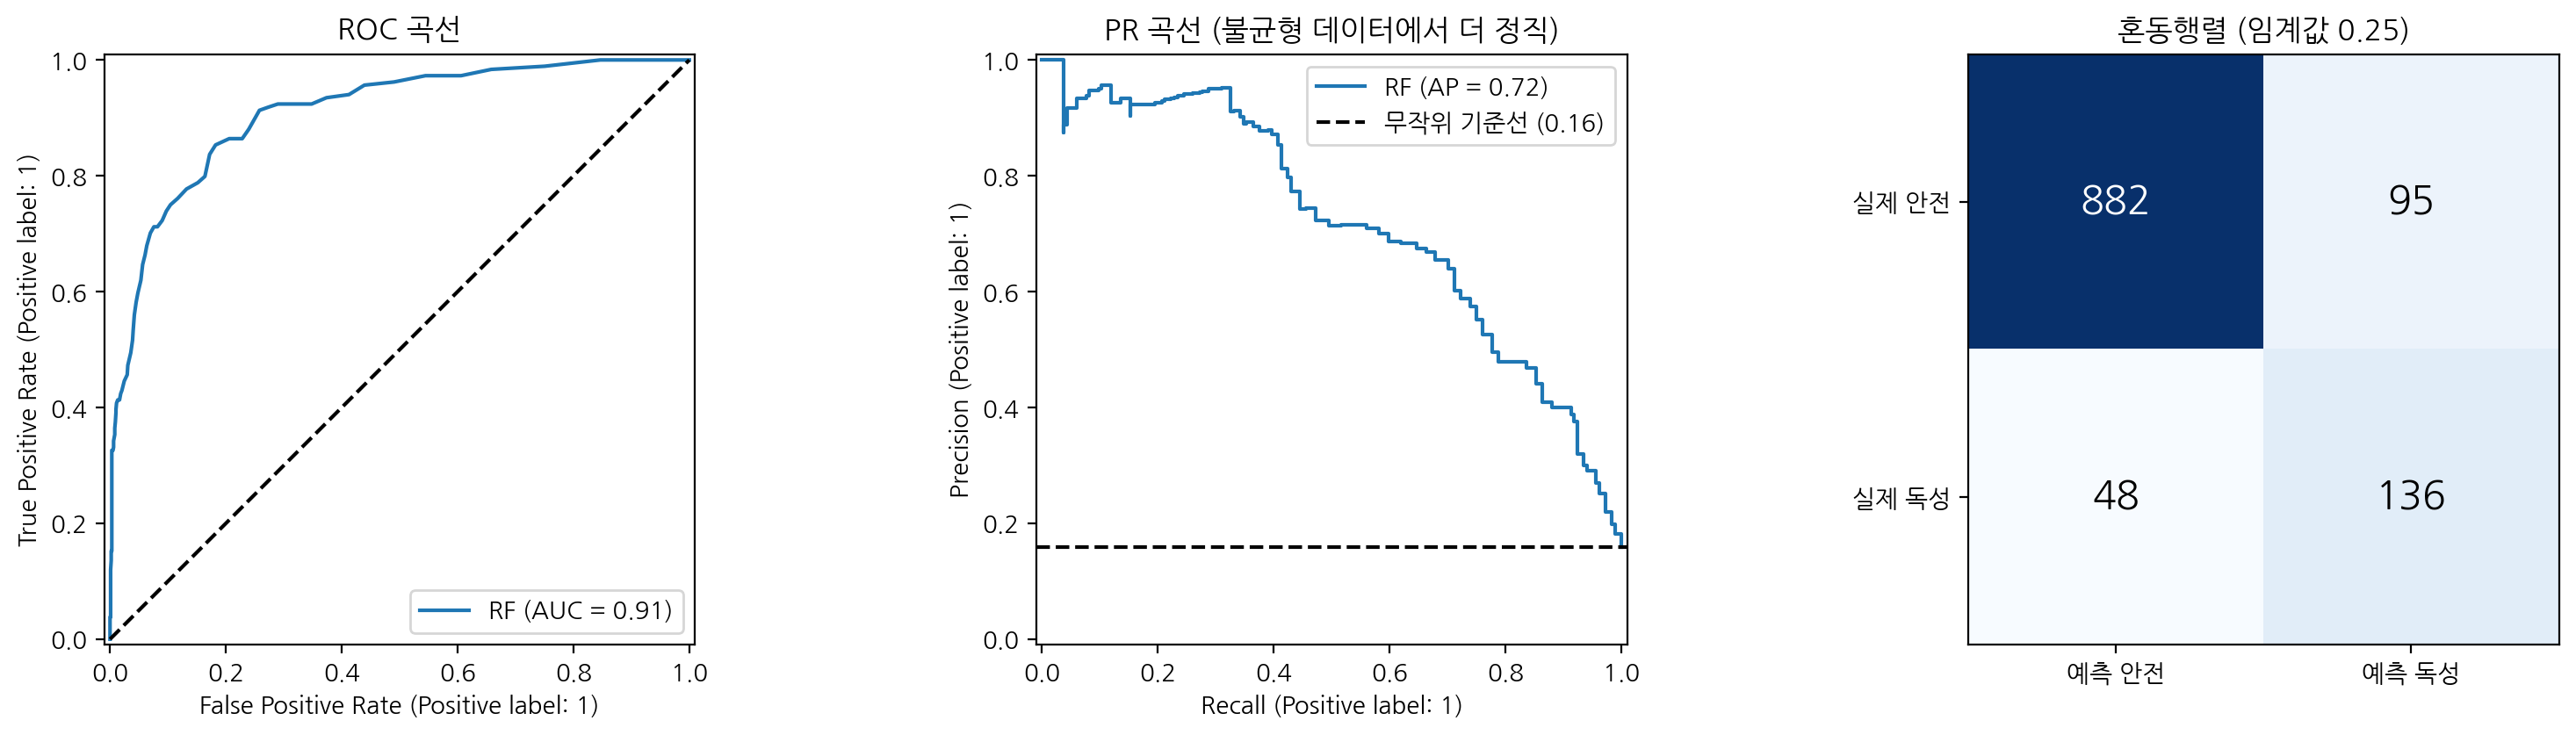

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
RocCurveDisplay.from_predictions(y_te, p_te, ax=ax[0], name="RF"); ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC 곡선")
PrecisionRecallDisplay.from_predictions(y_te, p_te, ax=ax[1], name="RF")
ax[1].axhline(y_te.mean(), color="k", ls="--", label=f"무작위 기준선 ({y_te.mean():.2f})"); ax[1].legend(); ax[1].set_title("PR 곡선 (불균형 데이터에서 더 정직)")
cm = confusion_matrix(y_te, (p_te >= th_rec80).astype(int))
ax[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, cm[i, j], ha="center", va="center", fontsize=16, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[2].set_xticks([0, 1], ["예측 안전", "예측 독성"]); ax[2].set_yticks([0, 1], ["실제 안전", "실제 독성"])
ax[2].set_title(f"혼동행렬 (임계값 {th_rec80:.2f})")
plt.tight_layout(); plt.show()

## 5. 비용 기반 의사결정 — "독성 1개를 놓치는 비용 = 오경보 10개"
FN(독성 놓침) 비용 10, FP(안전한데 독성 판정 → 추가 시험) 비용 1 로 가정하고 총비용이 최소인 임계값을 찾습니다.

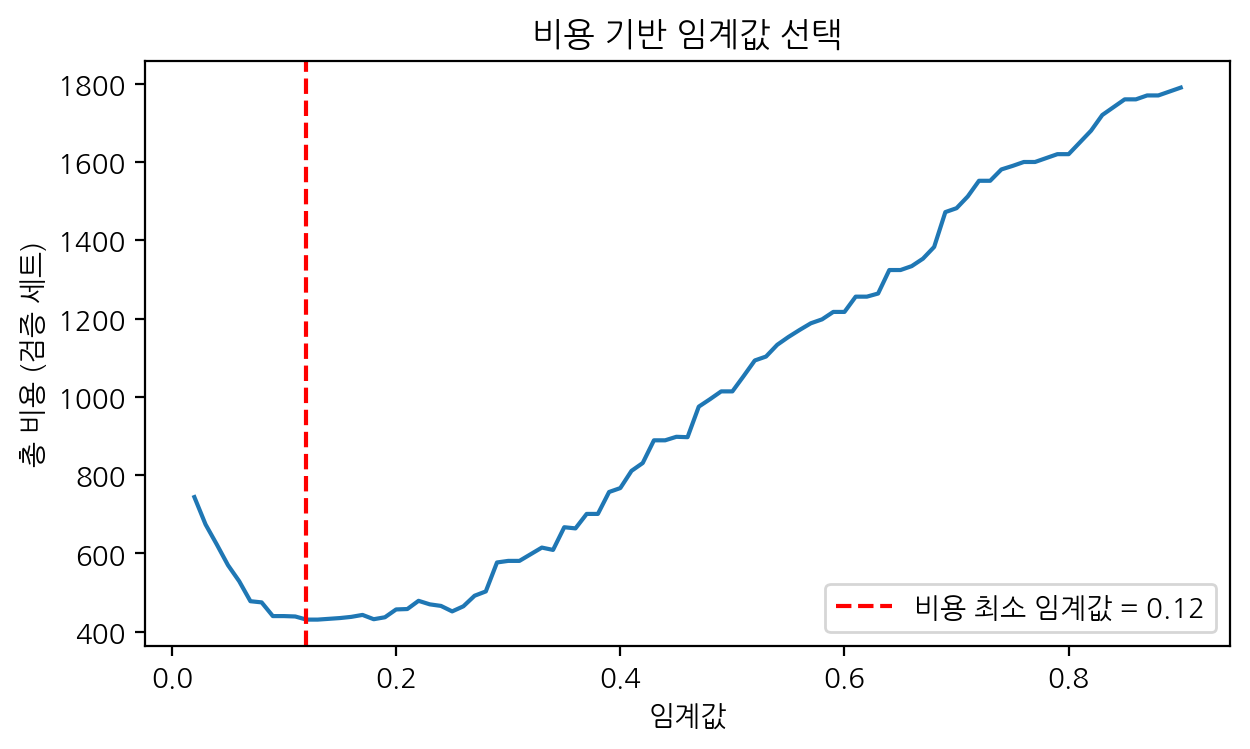

,모델,임계값,정확도,정밀도,재현율,F1,ROC-AUC,PR-AUC
0,RF + 비용최소 임계값,0.12,0.757,0.388,0.918,0.545,0.908,0.718


In [10]:
C_FN, C_FP = 10, 1
grid = np.linspace(0.02, 0.9, 89)
cost = []
for t in grid:
    tn, fp, fn, tp = confusion_matrix(y_va, (p_va >= t).astype(int)).ravel()
    cost.append(C_FN * fn + C_FP * fp)
th_cost = grid[int(np.argmin(cost))]
plt.figure(figsize=(7, 3.8)); plt.plot(grid, cost)
plt.axvline(th_cost, color="red", ls="--", label=f"비용 최소 임계값 = {th_cost:.2f}")
plt.xlabel("임계값"); plt.ylabel("총 비용 (검증 세트)"); plt.legend(); plt.title("비용 기반 임계값 선택"); plt.show()
pd.DataFrame([report("RF + 비용최소 임계값", y_te, p_te, th_cost)]).round(3)

## 6. 해석: 어떤 부분구조가 독성과 관련 있나?
랜덤포레스트가 중요하게 본 **Morgan 지문 비트**를 원래 분자 위에 그려 봅니다.
(독성 구조경고 **toxicophore**: 니트로방향족, 퀴논, 마이클 수용체 등)

bit 1602: 보유 분자의 독성률 48%
bit 1873: 보유 분자의 독성률 22%
bit 875: 보유 분자의 독성률 31%
bit 984: 보유 분자의 독성률 42%
bit 838: 보유 분자의 독성률 33%
bit 80: 보유 분자의 독성률 12%


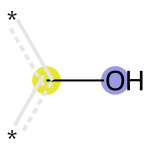

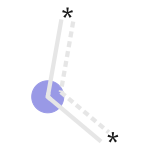

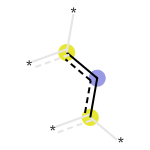

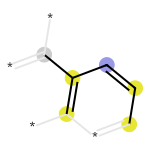

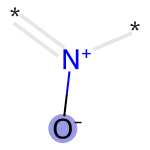

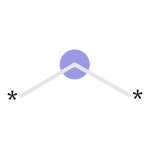

In [12]:
imp = rf.feature_importances_[:2048]
top_bits = np.argsort(imp)[::-1][:6]
pos_mols = d.loc[y == 1, "mol"].tolist()
imgs, legends = [], []
for b in top_bits:
    for m in pos_mols:
        ao = rdFingerprintGenerator.AdditionalOutput(); ao.AllocateBitInfoMap()
        fp = morgan.GetFingerprint(m, additionalOutput=ao)
        if fp.GetBit(int(b)):
            info = ao.GetBitInfoMap()
            imgs.append(Draw.DrawMorganBit(m, int(b), {int(b): info[int(b)]}, useSVG=False))
            rate = y[X_fp[:, b] == 1].mean()
            legends.append(f"bit {b}: 보유 분자의 독성률 {rate:.0%}")
            break
for im, lg in zip(imgs, legends):
    print(lg)
from IPython.display import display
for im in imgs: display(im)

## 7. 12개 독성 시험 전체 예측 (멀티 엔드포인트)
실무에서는 하나의 분자에 대해 여러 독성 시험 결과를 한꺼번에 예측합니다. 시험별 ROC-AUC 를 비교합니다.

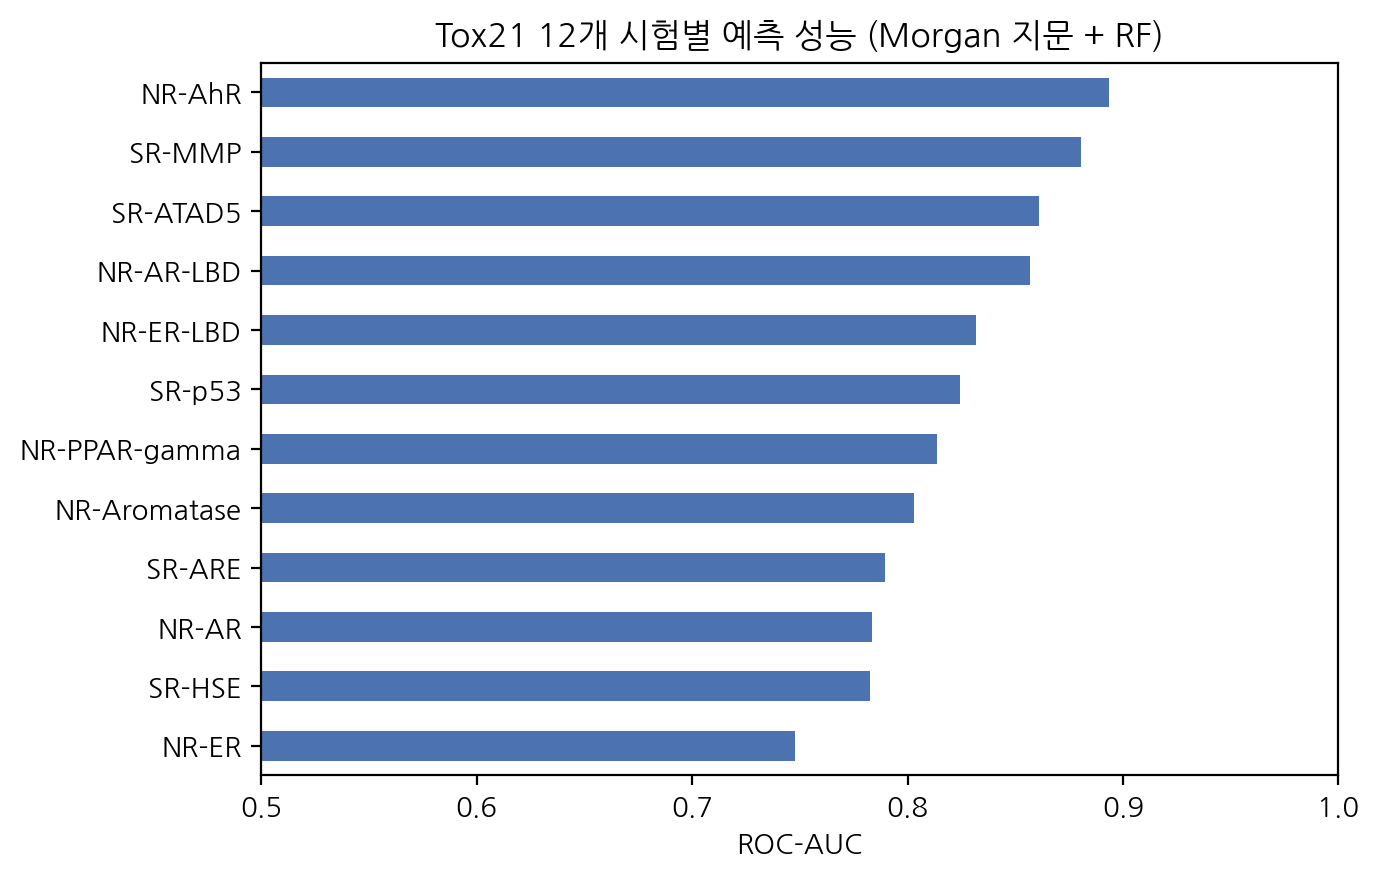

In [14]:
fp_all = {}
for i, s in enumerate(tox["smiles"]):
    m = Chem.MolFromSmiles(s)
    if m is not None: fp_all[i] = morgan.GetFingerprintAsNumPy(m)
auc = {}
for t in tasks:
    idx = [i for i in tox.index[tox[t].notna()] if i in fp_all]
    Xt = np.array([fp_all[i] for i in idx]); yt = tox.loc[idx, t].astype(int).values
    a, b, ya, yb = train_test_split(Xt, yt, test_size=0.2, stratify=yt, random_state=0)
    m = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0, class_weight="balanced_subsample").fit(a, ya)
    auc[t] = roc_auc_score(yb, m.predict_proba(b)[:, 1])
pd.Series(auc).sort_values().plot.barh(figsize=(7, 4.5), color="#4C72B0")
plt.xlim(0.5, 1); plt.xlabel("ROC-AUC"); plt.title("Tox21 12개 시험별 예측 성능 (Morgan 지문 + RF)"); plt.tight_layout(); plt.show()

## 8. 새 분자의 미토콘드리아 독성 위험 예측

In [15]:
new = {"FCCP (미토콘드리아 탈공역제)": "FC(F)(F)Oc1ccc(NN=C(C#N)C#N)cc1",
       "로테논 (복합체 I 억제제)": "CC(=C)C1CC2=C(O1)C=CC3=C2OC4COC5=CC(=C(C=C5C4C3=O)OC)OC",
       "아스피린": "CC(=O)Oc1ccccc1C(=O)O",
       "카페인": "CN1C=NC2=C1C(=O)N(C(=O)N2C)C"}
rows = []
for name, smi in new.items():
    m = Chem.MolFromSmiles(smi)
    dd = pd.DataFrame([Descriptors.CalcMolDescriptors(m)])[X_desc.columns].fillna(X_desc.median())
    x = np.hstack([morgan.GetFingerprintAsNumPy(m), dd.values[0]]).reshape(1, -1)
    p = rf.predict_proba(x)[0, 1]
    level = "⚠️ 독성 의심" if p >= th_rec80 else ("△ 경계 — 추가 시험 권장" if p >= 0.5 * th_rec80 else "낮음")
    rows.append({"분자": name, "SR-MMP 독성 확률": round(p, 3), f"판정 (임계값 {th_rec80:.2f})": level})
pd.DataFrame(rows)

,분자,SR-MMP 독성 확률,판정 (임계값 0.25)
0,FCCP (미토콘드리아 탈공역제),0.21,△ 경계 — 추가 시험 권장
1,로테논 (복합체 I 억제제),0.25,⚠️ 독성 의심
2,아스피린,0.02,낮음
3,카페인,0.02,낮음


> 모델 확률은 **절대적 판정이 아니라 위험 순위**로 해석합니다. 임계값 근처(경계) 분자는 실험(세포 기반 MMP 시험)으로 확인합니다.

## 🧪 LLM 코딩 과제
```
Tox21 데이터에서 'NR-AhR' 시험을 대상으로 Morgan 지문 + 로지스틱회귀(class_weight='balanced') 모델을 만들고,
랜덤포레스트와 ROC-AUC, PR-AUC, 재현율을 비교하는 표를 만들어줘. 학습/평가는 stratify 로 8:2 분할해줘.
```

In [ ]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리 & 현장 응용
| 주제 | 핵심 |
|---|---|
| 불균형 데이터 | 정확도는 무의미할 수 있음 → **재현율·PR-AUC** 확인, `stratify` 분할 |
| 대처법 | `class_weight`, **임계값 조정(검증 세트로!)**, 비용 기반 판단, (오버/언더샘플링) |
| 해석 | 중요 부분구조 = 독성 구조경고(toxicophore) 후보 → 화학자 검토 |
| 실무 | hERG 심독성, Ames 변이원성, DILI 간독성 예측. **ICH M7** 은 변이원성 불순물 평가에 (Q)SAR 2종(전문가 규칙 기반 + 통계 기반) 사용을 인정 |

➡️ **다음 예제 05**: 같은 분류 문제를 **딥러닝 모델(MLP·CNN·RNN·GNN·Transformer)** 로 풀어 비교합니다.